# Planetary Defense Analytics — 03: Case 2 Regression (Predict Diameter)

**Target:** `diameter` (km)  
**Data:** only rows where diameter is known (~135k of ~932k). The target is never imputed.

**Workflow:** load → filter rows → target transform (log10) → feature engineering → split → feature selection (3 methods) → 3 models (tracked in MLflow) → evaluation → save best model → SHAP.

## 1. Setup

In [18]:
import pandas as pd
import numpy as np
import os, time, warnings
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE, f_regression, mutual_info_regression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
import mlflow
import mlflow.sklearn

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42
os.makedirs("../models", exist_ok=True)

## 2. Load data and keep rows with a known diameter

In [19]:
df = pd.read_parquet("../data/cleaned.parquet")
reg = df.dropna(subset=['diameter', 'albedo', 'H']).copy()
print("All rows        :", len(df))
print("Rows for Case 2 :", len(reg), f"({len(reg)/len(df)*100:.1f}%)")

All rows        : 932337
Rows for Case 2 : 131237 (14.1%)


**Why not impute diameter?** It is the target. Filling it with a mean/median would train the model on invented answers.  
**Note on albedo:** for most catalogued objects, albedo and diameter come from the same infrared survey (NEOWISE), so albedo is available only when diameter is. The brief lists albedo as a predictor, so it is used — but in the app, the user must supply an albedo estimate.

## 3. Target distribution — why log10(diameter)

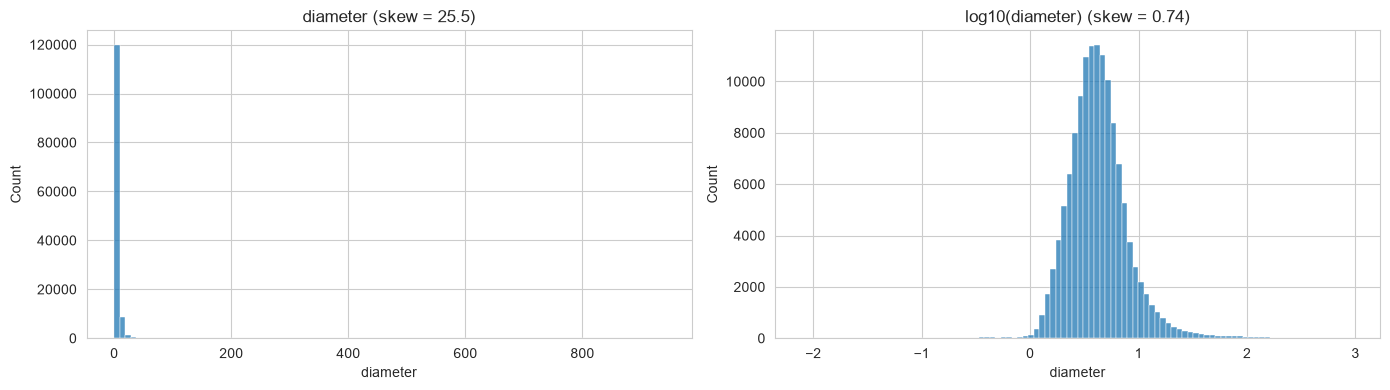

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(reg['diameter'], bins=100, ax=axes[0])
axes[0].set_title(f"diameter (skew = {reg['diameter'].skew():.1f})")
sns.histplot(np.log10(reg['diameter']), bins=100, ax=axes[1])
axes[1].set_title(f"log10(diameter) (skew = {np.log10(reg['diameter']).skew():.2f})")
plt.tight_layout(); plt.show()

**Observation:** raw diameter is extremely right-skewed (a few objects are hundreds of km, e.g. Ceres ≈ 940 km). The large objects are **real**, not errors, so they are kept — the log transform handles them instead of removing them.

**Physics:** D = 1329 / √albedo × 10^(−H/5)  →  log10(D) = 3.12 − 0.5·log10(albedo) − 0.2·H.  
So log10(diameter) is close to **linear** in `H` and `log10(albedo)`.

## 4. Feature engineering

In [21]:
def engineer_features(d):
    out = pd.DataFrame(index=d.index)
    out['H'] = d['H']
    out['log_albedo'] = np.log10(d['albedo'].clip(lower=1e-4))
    out['e'] = d['e']
    out['i'] = d['i']
    out['log_a'] = np.log10(d['a'])
    out['log_q'] = np.log10(d['q'])
    out['log_moid'] = np.log10(d['moid'] + 1e-6)
    for ang in ['om', 'w', 'ma']:
        rad = np.deg2rad(d[ang])
        out[f'{ang}_sin'] = np.sin(rad)
        out[f'{ang}_cos'] = np.cos(rad)
    if 'rms' in d.columns:
        out['log_rms'] = np.log10(d['rms'] + 1e-6)
    return out

X_all = engineer_features(reg)
y_all = np.log10(reg['diameter'])

mask = X_all.notna().all(axis=1) & np.isfinite(X_all).all(axis=1)
X_all, y_all = X_all[mask], y_all[mask]
print("Feature matrix:", X_all.shape)

Feature matrix: (131237, 14)


## 5. Train / test split (80/20)

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (104989, 14) | Test: (26248, 14)


## 6. Feature selection (3 methods, training data only)
### 6.1 Correlation with target

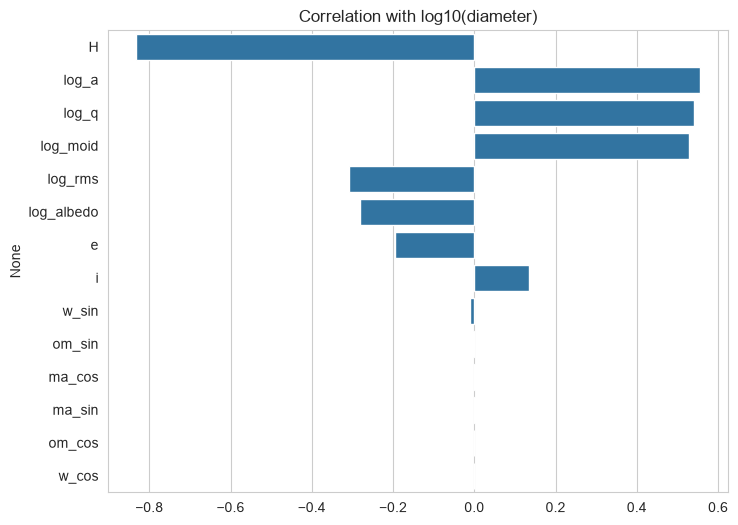

H            -0.831437
log_a         0.555765
log_q         0.540136
log_moid      0.527215
log_rms      -0.309651
log_albedo   -0.280966
e            -0.195268
i             0.134227
w_sin        -0.009526
om_sin       -0.004460
ma_cos        0.002891
ma_sin        0.001549
om_cos        0.000443
w_cos        -0.000357
Name: target, dtype: float64

In [23]:
corr = X_train.assign(target=y_train).corr()['target'].drop('target').sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(x=corr.values, y=corr.index)
plt.title("Correlation with log10(diameter)"); plt.show()
corr

### 6.2 Method 1 — Statistical tests (F-test + Mutual Information)

In [24]:
candidate_features = list(X_train.columns)
f_vals, p_vals = f_regression(X_train, y_train)
Xs = X_train.sample(min(30000, len(X_train)), random_state=RANDOM_STATE)
mi = mutual_info_regression(Xs, y_train.loc[Xs.index], random_state=RANDOM_STATE)
stat_df = pd.DataFrame({'feature': candidate_features, 'F': f_vals, 'p_value': p_vals,
                        'mutual_info': mi}).sort_values('mutual_info', ascending=False)
stat_df

,feature,F,p_value,mutual_info
1,log_albedo,8998.234554,0.000000,1.118712
0,H,235093.618473,0.000000,0.748512
6,log_moid,40415.418620,0.000000,0.250129
5,log_q,43246.752139,0.000000,0.242911
4,log_a,46920.321656,0.000000,0.240563
13,log_rms,11134.109479,0.000000,0.085786
2,e,4161.794379,0.000000,0.046224
3,i,1926.256421,0.000000,0.028670
7,om_sin,2.088433,0.148421,0.003783
12,ma_cos,0.877378,0.348923,0.003443


### 6.3 Method 2 — Tree-based importance (Random Forest)

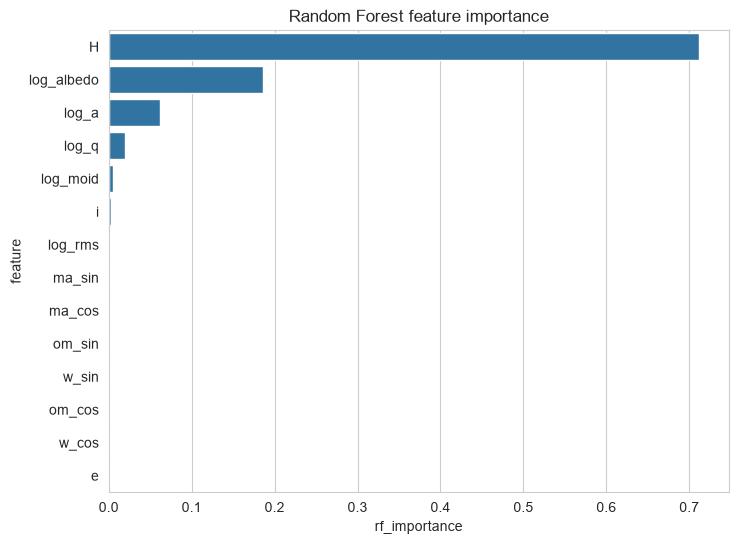

In [25]:
rf_fs = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=RANDOM_STATE)
rf_fs.fit(Xs, y_train.loc[Xs.index])
imp_df = pd.DataFrame({'feature': candidate_features,
                       'rf_importance': rf_fs.feature_importances_}).sort_values('rf_importance', ascending=False)
plt.figure(figsize=(8, 6))
sns.barplot(data=imp_df, x='rf_importance', y='feature')
plt.title("Random Forest feature importance"); plt.show()

### 6.4 Method 3 — RFE (Linear Regression)

In [26]:
rfe = RFE(LinearRegression(), n_features_to_select=8)
rfe.fit(StandardScaler().fit_transform(X_train), y_train)
rfe_df = pd.DataFrame({'feature': candidate_features, 'rfe_rank': rfe.ranking_}).sort_values('rfe_rank')
rfe_df

,feature,rfe_rank
0,H,1
1,log_albedo,1
2,e,1
3,i,1
4,log_a,1
5,log_q,1
6,log_moid,1
13,log_rms,1
8,om_cos,2
11,ma_sin,3


### 6.5 Consensus
Keep a feature if it is in the **top 8 of at least 2 of the 3 methods**. `H` and `log_albedo` are always kept — they are the physical basis of diameter.

In [27]:
TOP_K = 8
top_mi  = set(stat_df.nlargest(TOP_K, 'mutual_info')['feature'])
top_rf  = set(imp_df.nlargest(TOP_K, 'rf_importance')['feature'])
top_rfe = set(rfe_df[rfe_df['rfe_rank'] == 1]['feature'])

summary = pd.DataFrame({'feature': candidate_features})
summary['MI_top8'] = summary['feature'].isin(top_mi)
summary['RF_top8'] = summary['feature'].isin(top_rf)
summary['RFE_kept'] = summary['feature'].isin(top_rfe)
summary['votes'] = summary[['MI_top8', 'RF_top8', 'RFE_kept']].sum(axis=1)
summary = summary.sort_values('votes', ascending=False)

selected_features = summary[summary['votes'] >= 2]['feature'].tolist()
for must in ['H', 'log_albedo']:
    if must not in selected_features:
        selected_features.append(must)
print("Selected features:", selected_features)
summary

Selected features: ['H', 'log_albedo', 'i', 'log_a', 'log_q', 'log_moid', 'log_rms', 'e']


,feature,MI_top8,RF_top8,RFE_kept,votes
0,H,True,True,True,3
1,log_albedo,True,True,True,3
3,i,True,True,True,3
4,log_a,True,True,True,3
5,log_q,True,True,True,3
6,log_moid,True,True,True,3
13,log_rms,True,True,True,3
2,e,True,False,True,2
11,ma_sin,False,True,False,1
7,om_sin,False,False,False,0


## 7. Model training (3 models, tracked in MLflow)
Metrics are reported on two scales:
- **log scale** (what the model optimises) — R², RMSE, MAE of log10(diameter)
- **km scale** (after converting back with 10^prediction) — R², RMSE, MAE in km, easier to explain

In [28]:
mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("Case2_Diameter_Regression")

Xtr, Xte = X_train[selected_features], X_test[selected_features]

models = {
    "LinearRegression": Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    "RandomForest": Pipeline([('model', RandomForestRegressor(
        n_estimators=150, max_depth=20, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE))]),
    "XGBoost": Pipeline([('model', XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE))]),
}

def all_metrics(y_true_log, y_pred_log):
    yt, yp = 10 ** y_true_log, 10 ** y_pred_log
    return {
        'r2_log':   r2_score(y_true_log, y_pred_log),
        'rmse_log': np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        'mae_log':  mean_absolute_error(y_true_log, y_pred_log),
        'r2_km':    r2_score(yt, yp),
        'rmse_km':  np.sqrt(mean_squared_error(yt, yp)),
        'mae_km':   mean_absolute_error(yt, yp),
    }

results, fitted = [], {}
for name, pipe in models.items():
    t0 = time.time()
    with mlflow.start_run(run_name=name):
        pipe.fit(Xtr, y_train)
        pred = pipe.predict(Xte)
        m = all_metrics(y_test.values, pred)
        mlflow.log_params({'model': name, 'target': 'log10(diameter)',
                           'n_features': len(selected_features)})
        mlflow.log_params({k: v for k, v in pipe.named_steps['model'].get_params().items()
                           if k in ['n_estimators', 'max_depth', 'learning_rate', 'min_samples_leaf']})
        mlflow.log_metrics(m)
        mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")
    fitted[name] = pipe
    results.append({'model': name, **m, 'train_sec': round(time.time() - t0, 1)})
    print(f"{name:18s} R2(log)={m['r2_log']:.4f} RMSE(log)={m['rmse_log']:.4f} "
          f"MAE(km)={m['mae_km']:.3f}  ({time.time()-t0:.0f}s)")

2026/10/28 15:14:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LinearRegression   R2(log)=0.9651 RMSE(log)=0.0524 MAE(km)=0.492  (2s)


2026/10/28 15:14:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest       R2(log)=0.9742 RMSE(log)=0.0450 MAE(km)=0.433  (10s)


2026/10/28 15:14:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost            R2(log)=0.9732 RMSE(log)=0.0460 MAE(km)=0.545  (4s)


## 8. Model comparison

In [29]:
res_df = pd.DataFrame(results).sort_values('rmse_log').reset_index(drop=True)
res_df.round(4)

,model,r2_log,rmse_log,mae_log,r2_km,rmse_km,mae_km,train_sec
0,RandomForest,0.9742,0.0450,0.0318,0.8878,3.5900,0.4325,9.6
1,XGBoost,0.9732,0.0460,0.0321,0.6913,5.9543,0.5452,3.6
2,LinearRegression,0.9651,0.0524,0.0355,0.9650,2.0059,0.4922,2.3


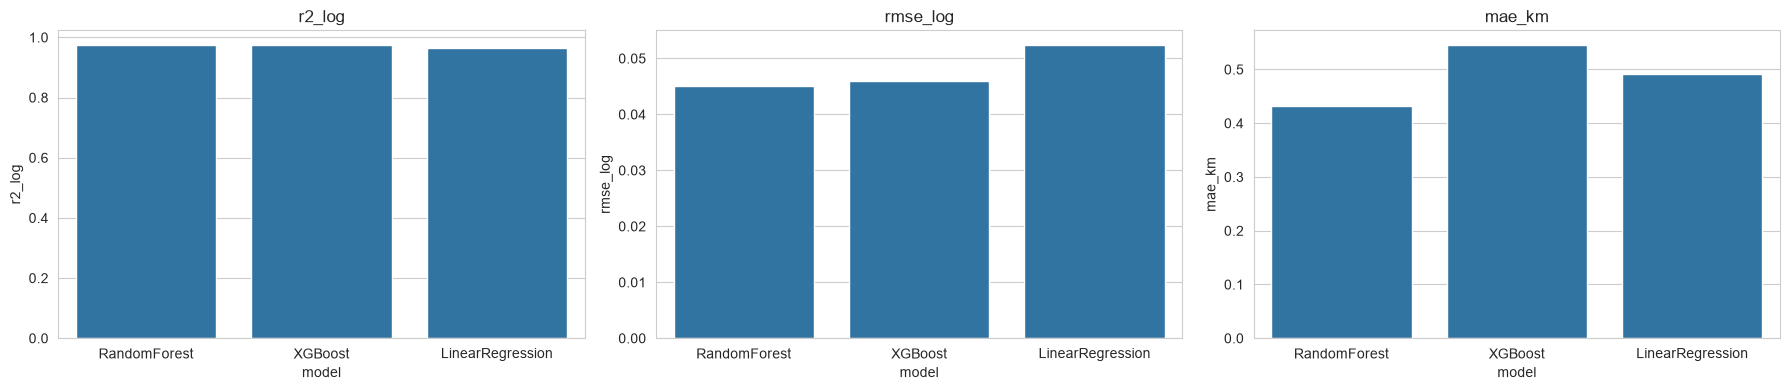

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, metric in zip(axes, ['r2_log', 'rmse_log', 'mae_km']):
    sns.barplot(data=res_df, x='model', y=metric, ax=ax)
    ax.set_title(metric)
plt.tight_layout(); plt.show()

**Metric choice:**
- **R²** — share of variation in size explained by the model.
- **RMSE** — penalises big misses more; important because over/under-estimating a large object's size changes its impact-risk assessment.
- **MAE** — typical error, easy to explain in km.
- Selection is by **RMSE on the log scale**, because on the km scale a few very large objects (hundreds of km) dominate the error.

## 9. Best model — actual vs predicted and residuals

Best model (lowest log RMSE): RandomForest


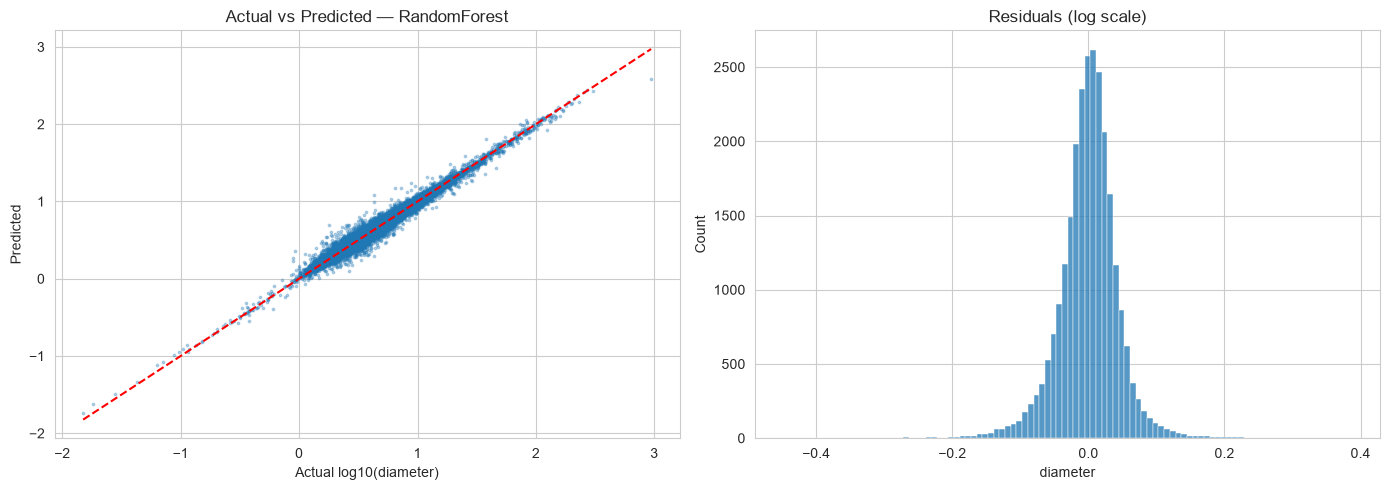

In [31]:
best_name = res_df.loc[0, 'model']
best_pipe = fitted[best_name]
pred_best = best_pipe.predict(Xte)
print("Best model (lowest log RMSE):", best_name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test, pred_best, s=3, alpha=0.3)
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, 'r--')
axes[0].set_xlabel("Actual log10(diameter)"); axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Actual vs Predicted — {best_name}")

resid = y_test - pred_best
sns.histplot(resid, bins=100, ax=axes[1])
axes[1].set_title("Residuals (log scale)")
plt.tight_layout(); plt.show()

**Interpretation:** points close to the red line = accurate predictions. Residuals centred on 0 and roughly symmetric mean the model is not systematically over- or under-estimating size.

## 10. Save best model

In [38]:
raw_cols = [c for c in ['H', 'albedo', 'e', 'i', 'a', 'q', 'moid', 'om', 'w', 'ma', 'rms'] if c in reg.columns]
artifact = {'pipeline': best_pipe, 'features': selected_features, 'model_name': best_name,
            'target_transform': 'log10',
            'raw_defaults': reg.loc[X_train.index, raw_cols].median().to_dict(),
            'background': Xtr.sample(200, random_state=RANDOM_STATE)}
joblib.dump(artifact, "../models/diameter_regressor.joblib", compress=3)
size_mb = os.path.getsize("../models/diameter_regressor.joblib") / 1e6
print(f"Saved ../models/diameter_regressor.joblib ({size_mb:.1f} MB)")
if size_mb > 95:
    print("WARNING: file > 95 MB — too large for GitHub. Use the XGBoost model instead.")

Saved ../models/diameter_regressor.joblib (0.8 MB)


## Deployment decision

Random Forest had the best RMSE (0.0450), but its saved file is 119 MB, above GitHub's 100 MB limit. **XGBoost** (RMSE 0.0460, R² 0.973) is deployed instead: 0.001 lower R² for a file 150× smaller (0.8 MB).

In [40]:
# Random Forest file is 119 MB (> GitHub 100 MB limit) -> use XGBoost for deployment
print(res_df[['model', 'r2_log', 'rmse_log', 'mae_km']].round(4))

best_name = 'XGBoost'
best_pipe = fitted[best_name]

artifact = {'pipeline': best_pipe, 'features': selected_features, 'model_name': best_name,
            'target_transform': 'log10',
            'raw_defaults': reg.loc[X_train.index, raw_cols].median().to_dict(),
            'background': Xtr.sample(200, random_state=RANDOM_STATE)}
joblib.dump(artifact, "../models/diameter_regressor.joblib", compress=3)
print(f"Saved {best_name}: {os.path.getsize('../models/diameter_regressor.joblib')/1e6:.1f} MB")

              model  r2_log  rmse_log  mae_km
0      RandomForest  0.9742    0.0450  0.4325
1           XGBoost  0.9732    0.0460  0.5452
2  LinearRegression  0.9651    0.0524  0.4922
Saved XGBoost: 0.8 MB


## 11. Explainable AI — SHAP

In [41]:
import shap

model_step = best_pipe.named_steps['model']
X_shap = Xte.sample(2000, random_state=RANDOM_STATE)
X_shap_t = (pd.DataFrame(best_pipe.named_steps['scaler'].transform(X_shap), columns=selected_features, index=X_shap.index)
            if 'scaler' in best_pipe.named_steps else X_shap)

explainer = (shap.LinearExplainer(model_step, X_shap_t) if isinstance(model_step, LinearRegression)
             else shap.TreeExplainer(model_step))
sv = explainer(X_shap_t)

### 11.1 Global importance

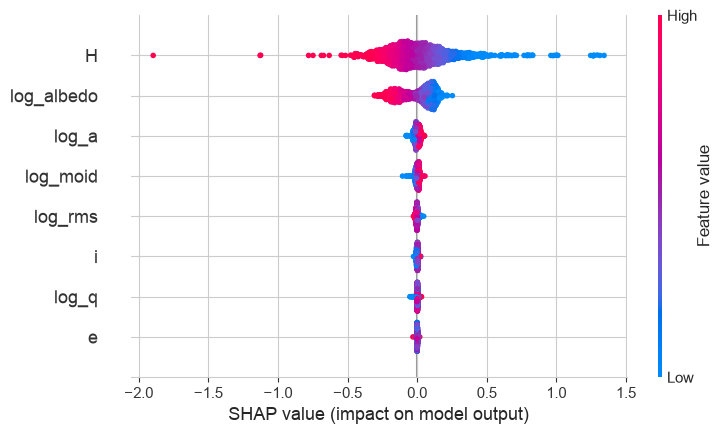

In [35]:
shap.plots.beeswarm(sv, max_display=12)

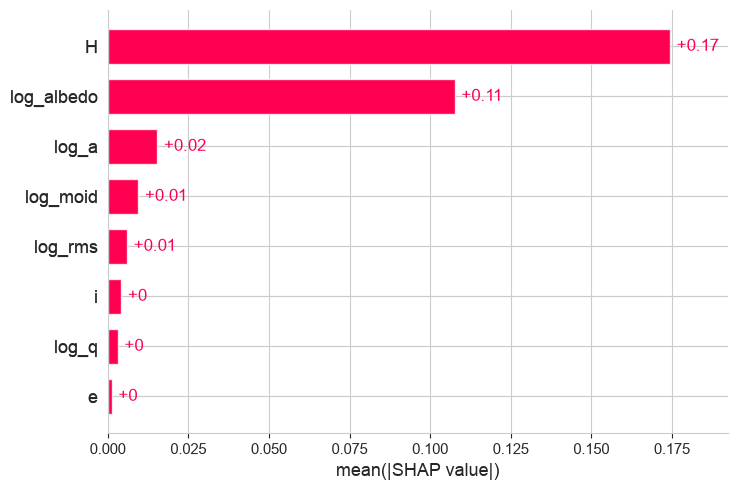

In [36]:
shap.plots.bar(sv, max_display=12)

### 11.2 Local explanation — one asteroid

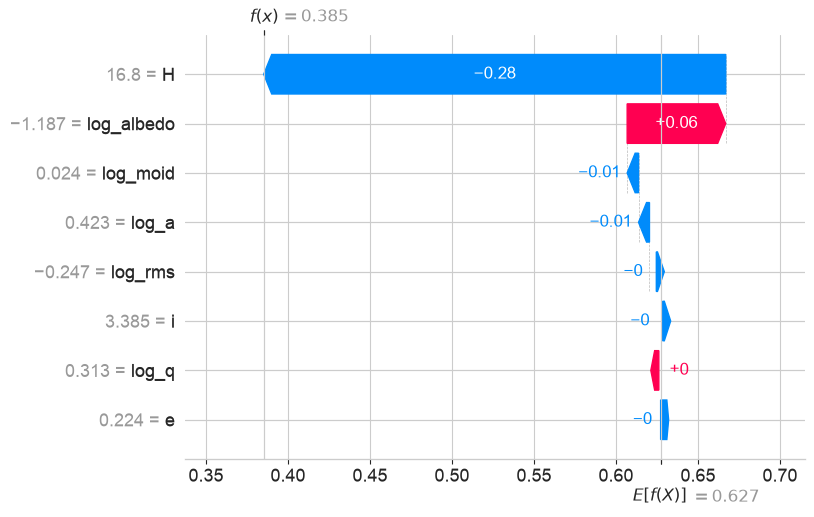

Predicted diameter: 2.428 km
Actual diameter   : 2.269 km


In [37]:
shap.plots.waterfall(sv[0], max_display=10)
print("Predicted diameter:", round(10 ** best_pipe.predict(X_shap.iloc[[0]])[0], 3), "km")
print("Actual diameter   :", round(10 ** y_test.loc[X_shap.index[0]], 3), "km")

**Discussion:**
- **H dominates:** higher H means a fainter object, which means a smaller diameter (negative SHAP). This matches the physics formula D = 1329 / √albedo × 10^(−H/5).
- **log_albedo is second:** for the same brightness, a darker surface (lower albedo) means a larger object. SHAP shows low albedo pushing the predicted diameter up.
- **Orbital features (e.g., log_moid):** have a smaller but visible effect. MOID has no physical link to size; it reflects **survey/discovery bias**: objects close to Earth are discovered at much smaller sizes than distant main-belt objects. This is noted as a limitation.
- **Agreement with feature selection:** H and log_albedo were also top-ranked by all 3 methods (statistical tests, Random Forest importance, RFE) in Section 6.5.
- **Model check:** for the app's Apollo example, the model predicted 357 m against 374 m from the physics formula (−4.5%), showing the model has learned the physical relationship.

## 12. Summary
- Trained on rows with known diameter only; target modelled as log10(diameter).
- 3 models compared and logged in MLflow (experiment `Case2_Diameter_Regression`).
- Best model saved to `models/diameter_regressor.joblib` (predictions must be converted back with 10^x).